# Label regimes

The label is `MVT − BLOCK`. Before any modelling the question is whether it always means the taxi time. Comparing it
with the delay `MVT − SCHED` splits the 2025 departures into four groups that do not overlap:

| Regime | Definition |
|---|---|
| artefact | label within 60 s of the delay, delay above 2000 s (usually an off-block recorded at the scheduled time) |
| on-time pushback | label within 60 s of the delay, delay up to 2000 s (looks the same, but is usually a normal taxi) |
| long taxi | label above 2 h and not one of the above |
| normal | everything else |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "pyproject.toml").is_file())
FEATURES = ROOT / "data/03_features"

In [2]:
columns = ["ADEP_mvt", "MVT_TIME_UTC_mvt", "SCHED_TIME_UTC_mvt", "TAXITIME_SEC_mvt", "delay_sec",
           "mvt_minus_aobt_sec"]
train = pd.read_parquet(FEATURES / "train_DEP_merged_sorted.parquet", columns=columns)
train = train.loc[pd.to_datetime(train["SCHED_TIME_UTC_mvt"], utc=True).dt.year.eq(2025)].reset_index(drop=True)
train["month"] = pd.to_datetime(train["MVT_TIME_UTC_mvt"], utc=True).dt.month
y, delay = train["TAXITIME_SEC_mvt"], train["delay_sec"]
print(f"{len(train):,} departures in 2025")

2,085,041 departures in 2025


In [3]:
same = (y - delay).abs() <= 60
train["regime"] = np.select([same & (delay > 2000), same, y > 7200], ["artefact", "on-time pushback", "long taxi"], "normal")
summary = train.groupby("regime")["TAXITIME_SEC_mvt"].agg(share="size", median="median", p99=lambda s: s.quantile(.99))
summary["share"] = summary["share"] / len(train) * 100
summary.round({"share": 2, "median": 0, "p99": 0})

,share,median,p99
regime,,,
artefact,0.34,2577.0,18067.0
long taxi,0.01,8330.0,87863.0
normal,90.42,910.0,2273.0
on-time pushback,9.23,927.0,1867.0


### Per airport

Artefacts are concentrated at a few airports, LIRF above all.

In [4]:
(pd.crosstab(train["ADEP_mvt"], train["regime"], normalize="index") * 100).round(2)

regime,artefact,long taxi,normal,on-time pushback
ADEP_mvt,,,,
EDDF,0.03,0.00,93.05,6.92
EDDM,0.04,0.00,89.68,10.28
EGLL,0.41,0.01,90.16,9.41
EHAM,0.03,0.00,93.08,6.89
LEBL,0.19,0.00,90.06,9.75
LEMD,0.08,0.00,91.39,8.53
LFPG,0.13,0.02,91.79,8.06
LIRF,2.73,0.03,79.24,17.99
LSZH,0.02,0.00,94.17,5.81


### Per month

The shares are stable over the year, so the regimes are not a seasonal effect.

In [5]:
(pd.crosstab(train["month"], train["regime"], normalize="index") * 100).round(2)

regime,artefact,long taxi,normal,on-time pushback
month,,,,
1,0.27,0.01,89.88,9.84
2,0.38,0.02,88.82,10.78
3,0.25,0.00,89.13,10.62
4,0.27,0.00,89.32,10.41
5,0.30,0.01,89.97,9.72
6,0.36,0.01,91.17,8.47
7,0.51,0.02,92.18,7.30
8,0.41,0.01,91.19,8.39
9,0.35,0.00,91.78,7.87


### Label against delay

Artefacts lie on the diagonal: their label grows with the delay instead of staying near the usual taxi time.

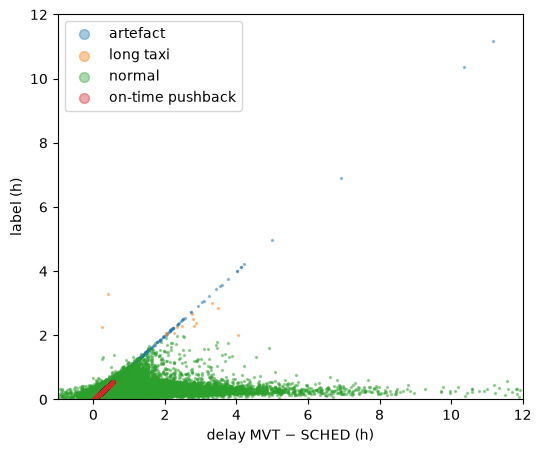

In [6]:
sample = train.sample(200_000, random_state=0)
fig, ax = plt.subplots(figsize=(6, 5))
for regime, group in sample.groupby("regime"):
    ax.scatter(group["delay_sec"] / 3600, group["TAXITIME_SEC_mvt"] / 3600, s=2, alpha=.4, label=regime)
ax.set(xlim=(-1, 12), ylim=(0, 12), xlabel="delay MVT − SCHED (h)", ylabel="label (h)")
ax.legend(markerscale=5)
plt.show()

### Why 2000 s

A label equal to the delay is a real taxi time if the aircraft really left at the scheduled time. The NM data give
an independent check: then `MVT − AOBT` (take-off minus the actual off-block reported to NM) also matches the
label. For an artefact the aircraft left later, so `MVT − AOBT` is clearly shorter. Share of the flights with label =
delay whose label matches `MVT − AOBT` within 5 min, by delay:

In [7]:
check = train.loc[same & train["mvt_minus_aobt_sec"].notna()]
consistent = (check["TAXITIME_SEC_mvt"] - check["mvt_minus_aobt_sec"]).abs() <= 300
delay_range = pd.cut(check["delay_sec"], [-np.inf, 600, 1200, 1500, 1800, 2000, 2200, 2500, 3000, 4000, np.inf])
pd.DataFrame({"flights": consistent.groupby(delay_range, observed=True).size(),
              "% matching AOBT": consistent.groupby(delay_range, observed=True).mean().mul(100).round(1)})

,flights,% matching AOBT
delay_sec,,
"(-inf, 600.0]",22432,77.1
"(600.0, 1200.0]",124391,79.6
"(1200.0, 1500.0]",29443,70.5
"(1500.0, 1800.0]",11989,48.4
"(1800.0, 2000.0]",3559,33.1
"(2000.0, 2200.0]",1739,21.6
"(2200.0, 2500.0]",1537,13.6
"(2500.0, 3000.0]",1267,7.1
"(3000.0, 4000.0]",1077,3.3


Up to about 1500 s most of these labels are real taxi times. Between 1500 s and 1800 s the share falls below one
half, and from 2000 s on about four out of five are artefacts, rising further with the delay. 2000 s was taken as the
point where artefacts clearly dominate. A higher limit such as 3000 s would treat the flights between 2000 s and
3000 s, mostly artefacts, as real taxi times; a lower one would call many real pushbacks artefacts. The limit was not
tuned further: close to it the classifier decides with its probability anyway.

### What follows for the models

- An artefact label is the delay, not a taxi time. A model that has to predict both cases with one number is pulled
  towards these labels for every delayed flight. The pipeline therefore estimates the probability that the label
  equals the delay separately (`08_classifier`) and combines both cases as an expected value.
- Up to a delay of about 2000 s a label equal to the delay is mostly a real taxi time, and the delay itself is a
  plausible taxi time, so only departures above 2000 s are classified.
- Artefacts and long taxis are rare but very large, so under squared error they matter far beyond their share. A
  second base model that never sees them (`07_base_b`) can focus on the normal traffic.